# Learn `data.py` and `model.py`

This notebook follows the project implementation: load and validate the 8×8 digit data, make reproducible train/validation/test splits, train the logistic-regression candidate and a dummy reference, then inspect metrics and quality gates.

**Start here:** select the project Python environment as the notebook kernel. The project requires Python 3.11–3.13. Run cells from top to bottom.


## 1. Prepare the notebook environment
Find the project `src` directory and add it to Python’s import path. This lets the copied model code import `vision_mlops.data`.

In [14]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
project_root = next((p for p in (cwd, *cwd.parents) if (p / "src" / "vision_mlops").is_dir()), None)
if project_root is None:
    raise FileNotFoundError("Open this notebook from the project folder, or set project_root to the project path.")
sys.path.insert(0, str(project_root / "src"))
print("Project:", project_root)
print("Python:", sys.version.split()[0])


Project: C:\Users\meisa\Desktop\Code\CI_CD\GPT_advance_CICD_course
Python: 3.10.11


## 2. `data.py`: load and validate the dataset
This cell copies the project’s `data.py` implementation. `load_dataset()` returns images shaped `(N, 8, 8)` and labels shaped `(N,)`. `validate_dataset()` raises an error if the input violates the expected data contract.

In [15]:
"""Load and validate the built-in scikit-learn handwritten-digit images."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SHAPE = (8, 8)
CLASSES = tuple(range(10))


def load_dataset():
    dataset = load_digits()
    images = np.asarray(dataset.images, dtype=np.float64)
    labels = np.asarray(dataset.target, dtype=np.int64)
    validate_dataset(images, labels)
    return images, labels


def validate_dataset(images, labels):
    if images.ndim != 3 or images.shape[1:] != IMAGE_SHAPE:
        raise ValueError("Expected images with shape (N, 8, 8)")
    if labels.shape != (len(images),):
        raise ValueError("Expected one label per image")
    if len(images) < 1000:
        raise ValueError("Unexpectedly small dataset")
    if not np.isfinite(images).all():
        raise ValueError("Images have non-finite values")
    if np.any((images < 0) | (images > 16)):
        raise ValueError("Pixel values must be in [0, 16]")
    if set(np.unique(labels)) != set(CLASSES):
        raise ValueError("Labels must cover classes 0 through 9")
    counts = np.bincount(labels, minlength=10)
    if counts.min() < 100:
        raise ValueError("Insufficient examples for at least one class")


def split_data(images, labels):
    # 60/20/20; first isolate test, then validation from development set.
    indices = np.arange(len(labels))
    dev_idx, test_idx = train_test_split(
        indices, test_size=0.20, random_state=SEED, stratify=labels
    )
    train_idx, val_idx = train_test_split(
        dev_idx, test_size=0.25, random_state=SEED, stratify=labels[dev_idx]
    )
    return (train_idx, val_idx, test_idx)


def to_features(images):
    images = np.asarray(images, dtype=np.float64)
    if images.ndim != 3 or images.shape[1:] != IMAGE_SHAPE:
        raise ValueError("Expected a batch of 8x8 images")
    return images.reshape(len(images), 64)


### Try loading and inspecting the data
Run this cell to see the sample count, shape, value range, and class counts.

In [16]:
images, labels = load_dataset()
print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Pixel range:", images.min(), "to", images.max())
print("Class counts:", np.bincount(labels))


Images: (1797, 8, 8) float64
Labels: (1797,) int64
Pixel range: 0.0 to 16.0
Class counts: [178 182 177 183 181 182 181 179 174 180]


### See one 8×8 digit
This visualization is optional; it helps connect the numeric matrix to the handwritten digit represented by its label.

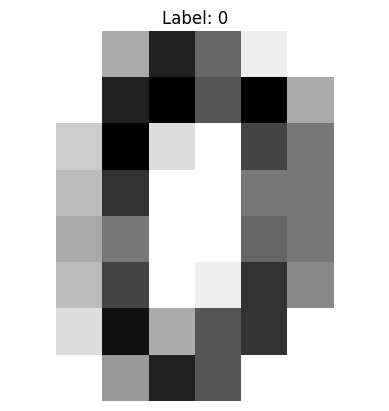

In [17]:
import matplotlib.pyplot as plt
sample = 0
plt.imshow(images[sample], cmap="gray_r")
plt.title(f"Label: {labels[sample]}")
plt.axis("off");


### Test that bad data is rejected
The original array is copied so this experiment does not corrupt `images`. The expected result is a `ValueError` mentioning non-finite values.

In [18]:
bad_images = images.copy()
bad_images[0, 0, 0] = np.nan
try:
    validate_dataset(bad_images, labels)
except ValueError as exc:
    print("Expected validation error:", exc)
else:
    raise AssertionError("Invalid data was not rejected")


Expected validation error: Images have non-finite values


### Create and inspect the data splits
`split_data()` uses a fixed seed and stratification. The test split is held aside; the model is trained only with `train_idx`. `to_features()` converts each 8×8 image into 64 features.

In [19]:
train_idx, val_idx, test_idx = split_data(images, labels)
print("Split sizes:", len(train_idx), len(val_idx), len(test_idx))
print("Any overlap:", bool(set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx)))
print("Feature matrix shape:", to_features(images[train_idx]).shape)
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(labels)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))


Split sizes: 1077 360 360
Any overlap: False
Feature matrix shape: (1077, 64)


## 3. `model.py`: candidate, reference, and metrics
The scaler is inside a scikit-learn `Pipeline`, so it learns its scaling values from the training data only. The reference model always predicts the most common training label; it is a simple baseline, not a previous production model. This notebook cell copies `model.py` from the project.

In [20]:
"""Candidate classifier, reference classifier, and evaluation metrics."""

from sklearn.dummy import DummyClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from vision_mlops.data import to_features

# This reference is a naive baseline, NOT an incumbent production model.
MIN_ACCURACY = 0.94
MIN_MACRO_F1 = 0.94
MIN_CLASS_RECALL = 0.80
MIN_GAIN_OVER_REFERENCE_F1 = 0.20


def new_candidate():
    # Fit scaler exclusively on train: prevents train/validation/test leakage.
    return Pipeline([
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42)),
    ])


def fit_models(images, labels, train_idx):
    X_train = to_features(images[train_idx])
    y_train = labels[train_idx]
    candidate = new_candidate()
    reference = DummyClassifier(strategy="most_frequent")
    candidate.fit(X_train, y_train)
    reference.fit(X_train, y_train)
    return candidate, reference


def metrics_for(model, images, labels):
    y_pred = model.predict(to_features(images))
    per_class = recall_score(labels, y_pred, average=None, labels=list(range(10)), zero_division=0)
    return {
        "accuracy": float(accuracy_score(labels, y_pred)),
        "macro_f1": float(f1_score(labels, y_pred, average="macro", zero_division=0)),
        "per_class_recall": [float(v) for v in per_class],
        "confusion_matrix": confusion_matrix(labels, y_pred, labels=list(range(10))).tolist(),
        "num_samples": int(len(labels)),
    }


def quality_failures(candidate_metrics, reference_metrics):
    problems = []
    if candidate_metrics["accuracy"] < MIN_ACCURACY:
        problems.append(f"accuracy {candidate_metrics['accuracy']:.3f} < {MIN_ACCURACY}")
    if candidate_metrics["macro_f1"] < MIN_MACRO_F1:
        problems.append(f"macro F1 {candidate_metrics['macro_f1']:.3f} < {MIN_MACRO_F1}")
    worst = min(candidate_metrics["per_class_recall"])
    if worst < MIN_CLASS_RECALL:
        problems.append(f"worst class recall {worst:.3f} < {MIN_CLASS_RECALL}")
    gain = candidate_metrics["macro_f1"] - reference_metrics["macro_f1"]
    if gain < MIN_GAIN_OVER_REFERENCE_F1:
        problems.append(f"F1 improvement over naive reference {gain:.3f} < {MIN_GAIN_OVER_REFERENCE_F1}")
    return problems


### Fit both models using only the training indices
The validation and test sets are not passed to `fit_models`, so they are not used to train the classifiers.

In [21]:
candidate, reference = fit_models(images, labels, train_idx)
print("Candidate:", candidate)
print("Reference:", reference)


Candidate: Pipeline(steps=[('scale', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])
Reference: DummyClassifier(strategy='most_frequent')


### Evaluate on validation data
Use validation metrics to inspect behavior while developing. The project pipeline records validation metrics, while its release quality gates are applied to the held-out test metrics.

In [22]:
validation_metrics = metrics_for(candidate, images[val_idx], labels[val_idx])
print("Validation accuracy:", round(validation_metrics["accuracy"], 4))
print("Validation macro F1:", round(validation_metrics["macro_f1"], 4))
print("Validation recall by digit:", [round(x, 3) for x in validation_metrics["per_class_recall"]])


Validation accuracy: 0.9722
Validation macro F1: 0.9724
Validation recall by digit: [1.0, 0.973, 0.971, 1.0, 0.972, 0.972, 0.944, 1.0, 0.971, 0.917]


### Evaluate once on held-out test data and check quality gates
This reproduces the project’s comparison. A passing result is an educational benchmark check, not proof of production readiness.

In [23]:
candidate_test = metrics_for(candidate, images[test_idx], labels[test_idx])
reference_test = metrics_for(reference, images[test_idx], labels[test_idx])
failures = quality_failures(candidate_test, reference_test)
print("Candidate test accuracy:", round(candidate_test["accuracy"], 4))
print("Candidate test macro F1:", round(candidate_test["macro_f1"], 4))
print("Candidate recall by digit:", [round(x, 3) for x in candidate_test["per_class_recall"]])
print("Reference test accuracy:", round(reference_test["accuracy"], 4))
print("Reference test macro F1:", round(reference_test["macro_f1"], 4))
print("Quality gate failures:", failures if failures else "None — passed")


Candidate test accuracy: 0.9583
Candidate test macro F1: 0.9577
Candidate recall by digit: [0.972, 0.861, 1.0, 1.0, 1.0, 1.0, 0.972, 1.0, 0.857, 0.917]
Reference test accuracy: 0.1
Reference test macro F1: 0.0182
Quality gate failures: None — passed


### Inspect predictions and the confusion matrix
Rows in the confusion matrix are true digits; columns are predicted digits. Off-diagonal values are mistakes.

In [24]:
print("First 10 true labels:     ", labels[test_idx[:10]])
print("First 10 predictions:    ", candidate.predict(to_features(images[test_idx[:10]])))
print("Confusion matrix (true rows × predicted columns):")
print(np.asarray(candidate_test["confusion_matrix"]))


First 10 true labels:      [5 2 8 1 7 2 6 2 6 5]
First 10 predictions:     [5 2 8 8 7 2 6 2 6 5]
Confusion matrix (true rows × predicted columns):
[[35  0  1  0  0  0  0  0  0  0]
 [ 0 31  0  1  0  0  0  0  3  1]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  4  0  0  0  1  0  0 30  0]
 [ 0  0  0  0  1  0  0  1  1 33]]


## What to experiment with
- Change a copied validation rule, then rerun the bad-data cell to see what it catches.
- Change `MIN_ACCURACY` or `MIN_MACRO_F1`, then rerun the quality-gate cell and inspect the failure messages.
- Replace the candidate classifier with a `DummyClassifier` in `new_candidate()`, refit, and see why quality gates matter.
- Restart the kernel and use **Run All** to confirm the notebook works from a clean state.

The model source cell imports `to_features` from `vision_mlops.data`; the setup cell adds the project’s `src` directory to Python’s module search path. No model file is written by these notebook exercises.

## 4. `pipeline.py`: connect data, model, evaluation, and artifacts

The pipeline is the end-to-end training entrypoint. It loads the data, creates the deterministic splits, checks that the splits do not overlap, fits both models on training data, evaluates validation and test sets, writes a JSON report, and saves the candidate model only when its quality checks pass.

**Safety for this lesson:** the experiment below writes into a temporary folder, so it won’t replace `models/metrics.json` or `models/model.joblib` in the project. The folder is deleted when the cell finishes.


### Read the project implementation
This cell copies the contents of `src/vision_mlops/pipeline.py`. Notice where the code delegates to `data.py` and `model.py`, and how it records the dataset hash and library versions.

In [ ]:
"""Training/evaluation entrypoint and immutable artifact metadata."""

import argparse
import hashlib
import json
import platform
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import sklearn

from vision_mlops.data import load_dataset, split_data
from vision_mlops.model import fit_models, metrics_for, quality_failures


def run_pipeline(output_dir, check_quality=True):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    images, labels = load_dataset()
    train_idx, val_idx, test_idx = split_data(images, labels)
    if (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx)):
        raise RuntimeError("Data splits overlap")
    candidate, reference = fit_models(images, labels, train_idx)
    val = metrics_for(candidate, images[val_idx], labels[val_idx])
    # Evaluate test exactly once for this fixed training specification.
    candidate_test = metrics_for(candidate, images[test_idx], labels[test_idx])
    reference_test = metrics_for(reference, images[test_idx], labels[test_idx])
    failures = quality_failures(candidate_test, reference_test)
    dataset_hash = hashlib.sha256(images.tobytes() + labels.tobytes()).hexdigest()
    report = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "dataset": "sklearn.load_digits (8x8 grayscale images)",
        "dataset_sha256": dataset_hash,
        "seed": 42,
        "split_sizes": {"train": len(train_idx), "validation": len(val_idx), "test": len(test_idx)},
        "validation": val,
        "test": candidate_test,
        "naive_reference_test": reference_test,
        "quality_passed": not failures,
        "quality_failures": failures,
        "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "numpy": np.__version__},
        "warning": "Educational handwritten-digit classifier; not a production incumbent comparison.",
    }
    (output_dir / "metrics.json").write_text(json.dumps(report, indent=2) + "\n")
    # Only export the candidate model when the quality criteria pass.
    if not failures:
        joblib.dump(candidate, output_dir / "model.joblib")
    return report


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--output-dir", default="models")
    parser.add_argument("--allow-fail", action="store_true", help="Diagnostic only; does not bypass artifact gate")
    args = parser.parse_args()
    report = run_pipeline(args.output_dir)
    print(json.dumps({"test": report["test"], "quality_passed": report["quality_passed"], "quality_failures": report["quality_failures"]}, indent=2))
    if not report["quality_passed"] and not args.allow_fail:
        raise SystemExit(1)


In [32]:
#output_dir = Path.cwd() / "test_code"
output_dir = Path.cwd() / "models"
run_pipeline(output_dir)

{'created_at_utc': '2026-11-13T04:24:16.041652+00:00',
 'dataset': 'sklearn.load_digits (8x8 grayscale images)',
 'dataset_sha256': 'f6d9e39f37dc45d327f6db33428ee58970ccceabb2535a5c179de35886b70443',
 'seed': 42,
 'split_sizes': {'train': 1077, 'validation': 360, 'test': 360},
 'validation': {'accuracy': 0.9722222222222222,
  'macro_f1': 0.9723752603395079,
  'per_class_recall': [1.0,
   0.972972972972973,
   0.9714285714285714,
   1.0,
   0.9722222222222222,
   0.9722222222222222,
   0.9444444444444444,
   1.0,
   0.9714285714285714,
   0.9166666666666666],
  'confusion_matrix': [[36, 0, 0, 0, 0, 0, 0, 0, 0, 0],
   [0, 36, 0, 0, 0, 0, 0, 0, 0, 1],
   [0, 1, 34, 0, 0, 0, 0, 0, 0, 0],
   [0, 0, 0, 37, 0, 0, 0, 0, 0, 0],
   [0, 0, 0, 0, 35, 0, 0, 1, 0, 0],
   [0, 0, 0, 0, 0, 35, 0, 0, 0, 1],
   [0, 1, 0, 0, 0, 1, 34, 0, 0, 0],
   [0, 0, 0, 0, 0, 0, 0, 36, 0, 0],
   [0, 0, 0, 0, 1, 0, 0, 0, 34, 0],
   [0, 2, 0, 0, 0, 0, 0, 0, 1, 33]],
  'num_samples': 360},
 'test': {'accuracy': 0.9583333

### Run the full pipeline into a temporary folder
The assertions below check the main outcomes: the quality gate passed, all 1,797 examples were assigned to a split, and both the report and model artifact were created.

In [28]:
import tempfile
import joblib
from pathlib import Path

with tempfile.TemporaryDirectory(prefix="vision_mlops_pipeline_") as temp_dir:
    output_dir = Path(temp_dir)
    pipeline_report = run_pipeline(output_dir)
    metrics_path = output_dir / "metrics.json"
    model_path = output_dir / "model.joblib"

    print("Quality passed:", pipeline_report["quality_passed"])
    print("Quality failures:", pipeline_report["quality_failures"])
    print("Split sizes:", pipeline_report["split_sizes"])
    print("Test accuracy:", round(pipeline_report["test"]["accuracy"], 4))
    print("Test macro F1:", round(pipeline_report["test"]["macro_f1"], 4))
    print("Metrics file exists:", metrics_path.is_file())
    print("Model file exists:", model_path.is_file())

    assert pipeline_report["quality_passed"]
    assert sum(pipeline_report["split_sizes"].values()) == len(labels)
    assert metrics_path.is_file() and model_path.is_file()

    saved_report = json.loads(metrics_path.read_text(encoding="utf-8"))
    saved_model = joblib.load(model_path)
    sample_predictions = saved_model.predict(to_features(images[:5]))
    print("Predictions from saved model:", sample_predictions)
    print("Dataset hash matches returned report:", saved_report["dataset_sha256"] == pipeline_report["dataset_sha256"])
    assert saved_report["dataset_sha256"] == pipeline_report["dataset_sha256"]


Quality passed: True
Quality failures: []
Split sizes: {'train': 1077, 'validation': 360, 'test': 360}
Test accuracy: 0.9583
Test macro F1: 0.9577
Metrics file exists: True
Model file exists: True
Predictions from saved model: [0 1 2 3 4]
Dataset hash matches returned report: True


### How to read the result
- `split_sizes` should be 1,077 train, 360 validation, and 360 test examples for this dataset.
- The report contains validation metrics for development inspection and test metrics for the configured quality gates.
- `quality_failures` is an empty list when every gate passes.
- The joblib artifact is loaded and used to predict five examples before the temporary folder is removed.

**Code detail:** `run_pipeline` currently accepts `check_quality=True`, but that argument is not used. Regardless of that argument, model export is gated on the computed quality failures. On a failed run, metrics are still written, but no candidate model is saved. Run this lesson from a clean kernel after the earlier setup, data, and model cells.


## 5. `plot_report.py`: turn metrics into figures

This script reads `models/metrics.json` and creates two figures: a confusion matrix and recall by digit. The figures help reveal which classes are being confused, even when the aggregate accuracy looks good.

The source cell below keeps the script’s `main()` function but does not invoke it automatically. We will run it from a temporary working directory so the exercise won’t overwrite the project’s existing report images.


### Read the project implementation
Follow how the JSON report is loaded, converted to NumPy arrays, plotted with Matplotlib, and saved as PNG files.

In [33]:
"""Generate auditable training figures from a saved evaluation report."""

import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np


def main():
    output_dir = Path("reports")
    output_dir.mkdir(exist_ok=True)
    path = Path("models/metrics.json")
    report = json.loads(path.read_text())
    matrix = np.asarray(report["test"]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set(title="Held-out test confusion matrix", xlabel="Predicted digit", ylabel="True digit", xticks=range(10), yticks=range(10))
    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(output_dir / "confusion_matrix.png", dpi=170)
    plt.close(fig)

    recalls = report["test"]["per_class_recall"]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(range(10), recalls)
    ax.set(title="Test recall by digit", xlabel="True digit", ylabel="Recall", xticks=range(10), ylim=(0, 1.05))
    fig.tight_layout()
    fig.savefig(output_dir / "per_class_recall.png", dpi=170)
    plt.close(fig)


# In the notebook, run main() from the safe temporary-folder exercise below.


### Run it safely and display the generated charts
This uses the `pipeline_report` created in the pipeline exercise. The script still reads the expected relative path `models/metrics.json`, but we create that path only inside a temporary directory for this run.

Created both plots in a temporary folder.


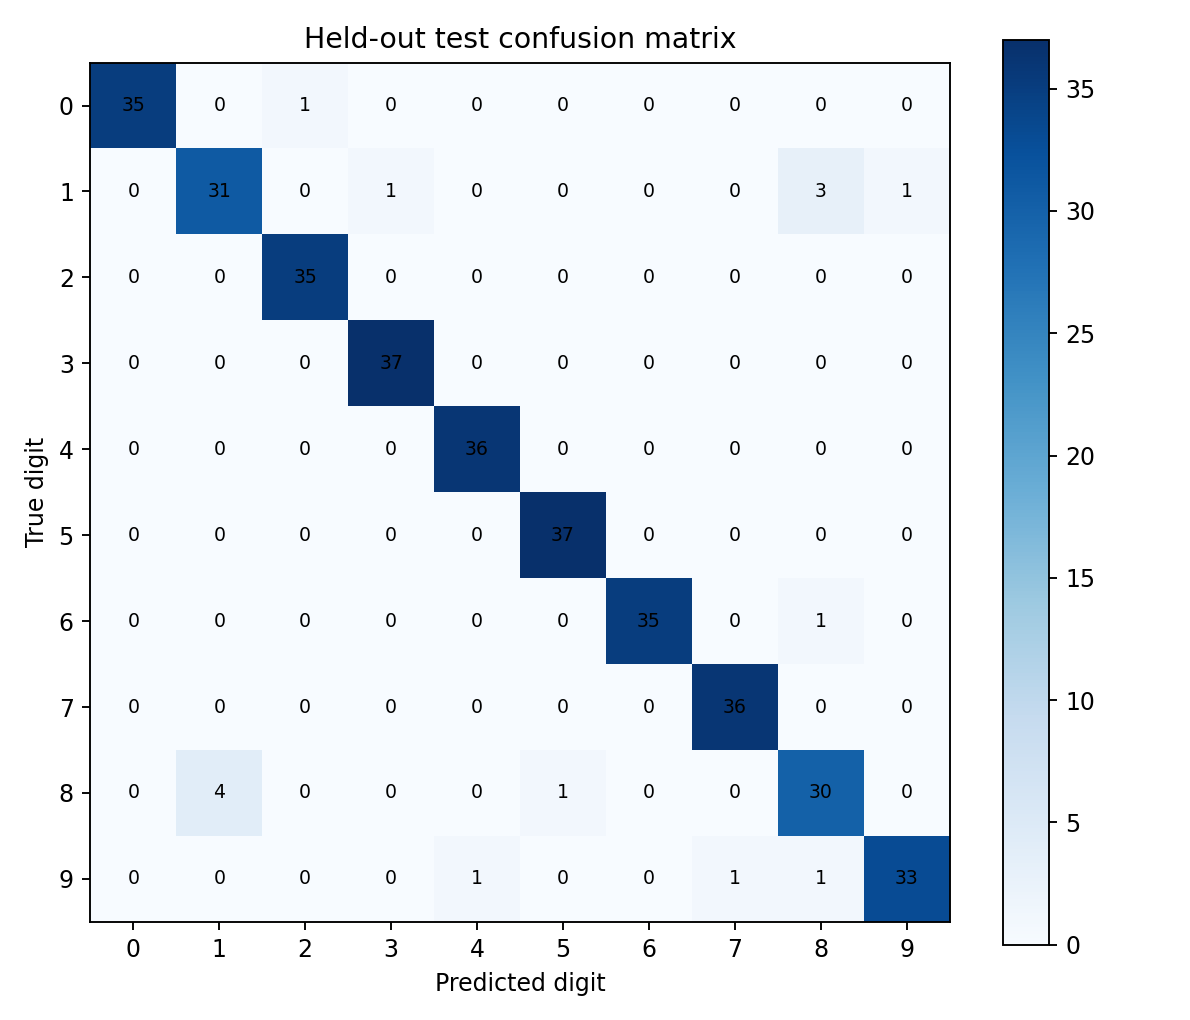

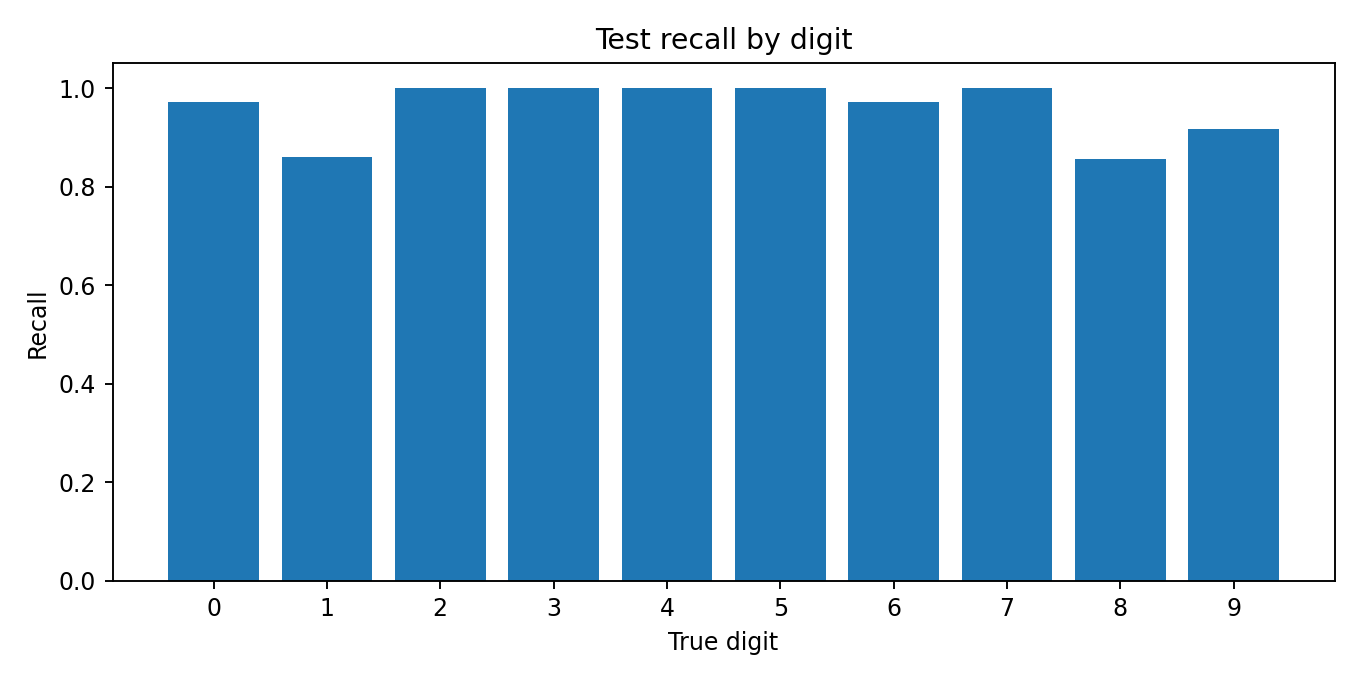

In [34]:
import os
import tempfile
from IPython.display import Image, display

with tempfile.TemporaryDirectory(prefix="vision_mlops_plots_") as temp_dir:
    temp_root = Path(temp_dir)
    (temp_root / "models").mkdir()
    (temp_root / "models" / "metrics.json").write_text(json.dumps(pipeline_report, indent=2), encoding="utf-8")
    original_cwd = Path.cwd()
    try:
        os.chdir(temp_root)
        main()
    finally:
        os.chdir(original_cwd)

    confusion_plot = temp_root / "reports" / "confusion_matrix.png"
    recall_plot = temp_root / "reports" / "per_class_recall.png"
    assert confusion_plot.is_file() and recall_plot.is_file()
    print("Created both plots in a temporary folder.")
    display(Image(filename=str(confusion_plot)))
    display(Image(filename=str(recall_plot)))


### How to interpret the figures
- In the confusion matrix, rows are actual digits and columns are predicted digits. Large diagonal values are correct predictions; values away from the diagonal are errors.
- In the recall chart, each bar is the fraction of examples for that true digit that the model recognized correctly.
- This script visualizes the stored metrics; it does not train or evaluate a model itself.

Run the notebook from the top so `pipeline_report` exists before running this plotting exercise. The temporary files are removed when the cell completes.
